# 11. 진단 — 겨울 사진이 "같은 나무, 다른 값"의 주범인가 (재학습 없음, 몇 분)

**한 줄 요약:** 같은 지수의 여름판(6–9월)과 겨울판(11–2월)에서, 같은 클래스가 지역마다 얼마나 다르게 찍히는지 비교한다. RF를 쓰지 않고 05 캐시의 위성 값만 본다.

**쉬운 설명**
- 지금 모델은 사진 두 장(여름·겨울)을 보고, 판별의 핵심은 겨울 사진이다
- 가설: 같은 "11–2월"이라도 남쪽은 잎이 덜 졌고, 북쪽·고지대는 눈·그림자가 있다 → 같은 나무가 지역마다 다르게 찍힌다
- 맞다면: 결과 숫자 보정으로는 못 고친다 → 사진을 바꾸는 v2(계절 맞춤 합성 + 지형)로 간다
- 틀리다면: 이 가설은 접는다

**재는 것 (지수마다 여름판 vs 겨울판)**
1. **흔들림 비율** = 같은 클래스의 지역 간 흔들림(지역 중앙값의 표준편차) ÷ 침엽–활엽 차이(지역 안). 클수록 "신호보다 지역 차이가 크다"
2. **지역 간 뒤집힘** = "다른 지역의 활엽이 이 지역의 침엽보다 더 침엽처럼 보이는" 지역 쌍 비율 (56쌍)
3. (기록만) **눈 흔적**: 지역별 겨울 NDSI = (B3−B11)/(B3+B11) 중앙값, 탄소 오차(실험 2 α=0)와의 관계. n=8이라 결론 안 냄

**순서:** [1] 설정 → [2] 사전 기록(확정 전엔 멈춤) → [3] 함수 → [4] 캐시 읽기·중앙값 계산 → [5] 주 결과·판정 → [6] 기록만 → [7] 그림·저장

**끊겼을 때:** `모두 실행` 다시. 원본 수정 없음.


In [3]:
# [1] 설정 — 09 [1]과 같은 경로·지역. RF 없음
import os, json, time, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/forest/outputs'

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
LAT  = {'inje': 38.04, 'hongcheon': 37.75, 'gangneung': 37.71, 'pyeongchang': 37.54,
        'bonghwa': 36.92, 'geumsan': 36.13, 'geochang': 35.71, 'suncheon': 35.01}
ELEV = {'inje': 622, 'hongcheon': np.nan, 'gangneung': 434, 'pyeongchang': 760,        # 인수인계 22절 표, 홍천·순천 미기록
        'bonghwa': 561, 'geumsan': 284, 'geochang': 550, 'suncheon': np.nan}
CLS = {1: '침엽', 2: '활엽', 3: '혼효'}

# 20밴드 순서 (인수인계 9절): 0–9 = 6–9월, 10–19 = 11–2월, 각각 B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12
BAND = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

for r in TRAIN_REGIONS:
    assert os.path.exists(f'{OUT}/{r}_s05.npz'), f'05 캐시 없음: {r}'
z = np.load(f'{OUT}/exp4c_results.npz')
assert list(z['regions']) == TRAIN_REGIONS
E0 = z['e0'].mean(0)                      # 실험 2(=09 α=0) 지역 탄소 오차, 5시드 평균 (%)
print('캐시 8곳·09 결과 확인 완료')
print('α=0 탄소 오차(%):', dict(zip(TRAIN_REGIONS, E0.round(2))))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
캐시 8곳·09 결과 확인 완료
α=0 탄소 오차(%): {'inje': np.float64(2.4), 'hongcheon': np.float64(0.73), 'gangneung': np.float64(-0.47), 'pyeongchang': np.float64(2.38), 'bonghwa': np.float64(1.19), 'geumsan': np.float64(2.17), 'geochang': np.float64(0.38), 'suncheon': np.float64(-1.36)}


## 진단 사전 기록 — 결과를 보기 전에 확정

**읽어 보고 맞으면 [2]의 `CONFIRMED = True`로 바꾼 뒤 실행.**

| 항목 | 내용 |
|---|---|
| 자료 | 05 캐시 8곳 전체 픽셀(지역당 약 60만, 2024+ 라벨, 클래스 1–3). RF 없음 |
| 지수 쌍 (여름판 vs 겨울판) | NDVI(피처 20 vs 21), NDMI(22 vs 23), NDSI(B3·B11로 계산), 밴드 10개(k vs 10+k) |
| 흔들림 비율 | [클래스별 지역 중앙값의 표준편차(8곳), 3클래스 평균] ÷ [지역 안 \|침엽 중앙값 − 활엽 중앙값\|의 8곳 평균] |
| 지역 간 뒤집힘 | 전체 방향(8곳 평균에서 침엽−활엽의 부호)과 반대인 (지역 r1 침엽, 지역 r2 활엽) 쌍의 비율, r1 ≠ r2, 56쌍 |
| **결정 규칙** | NDVI와 NDMI **둘 다**: 겨울판 흔들림 비율 > 여름판 **AND** 겨울판 뒤집힘 > 여름판 → "겨울 사진이 주원인 후보" → v2 데이터 설계. 하나라도 아니면 → 가설 접고 다른 원인 |
| 사전 예측 [추정] | 규칙 충족. 겨울 NDSI는 북쪽·고지대(평창·인제·홍천)가 높고, 겨울 NDSI–탄소 오차 ρ > 0 |
| 기록만 | 밴드별 비율, 지역별 겨울 NDSI 중앙값·0.4 초과 비율(관례적 눈 기준, 중앙값 합성이라 참고만), 클래스별 지역 중앙값 표, NDSI·고도·위도와 오차의 순위상관(n=8, 결론 없음) |
| 한계 | 중앙값만 본다(분포 겹침은 안 봄). 원인이 계절 단계인지 눈인지 그림자인지는 이 진단으로 구분 못 함 |

한 번 저장된 `diag_season_prereg.json`은 덮어쓰지 않는다.


In [4]:
# [2] 사전 기록 — 확정 전에는 여기서 멈춘다 (정상 정지)
CONFIRMED = True   # ← 위 표를 읽고 맞으면 True로 바꾼다

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'seen_before_prereg': ('실험 2–5 결과 전체, 28절 표(w_ndvi 지역 중앙값), [17] 클래스별 w_ndvi 중앙값(순천 활엽 0.515, 홍천 침엽 0.538). '
                           '여름판 지수의 지역·클래스별 중앙값과 NDSI는 본 적 없음'),
    'purpose': '여름판보다 겨울판에서 같은 클래스가 지역마다 더 다르게 찍히는가 (겨울 사진이 지역 의존의 주원인 후보인가)',
    'data': '05 캐시 {r}_s05.npz 8곳 전체 픽셀. RF 없음',
    'pairs': {'NDVI': '피처 20 vs 21', 'NDMI': '피처 22 vs 23', 'NDSI': 'nd(B3,B11) 여름 vs 겨울', 'bands': '밴드 k vs 10+k'},
    'metric_ratio': '클래스별 지역 중앙값 SD(ddof=1, 8곳)의 3클래스 평균 ÷ 지역 안 |침엽−활엽 중앙값|의 8곳 평균',
    'metric_inversion': '8곳 평균 기준 침엽−활엽 부호와 반대인 (r1 침엽, r2 활엽) 쌍 비율, r1≠r2, 56쌍',
    'decision_rule': 'NDVI·NDMI 둘 다: 겨울 비율 > 여름 비율 AND 겨울 뒤집힘 > 여름 뒤집힘 → 겨울 사진 주원인 후보 → v2 데이터 설계. 아니면 가설 접음',
    'prediction': '[추정] 규칙 충족. 겨울 NDSI 상위 = 평창·인제·홍천. 겨울 NDSI–탄소 오차 순위상관 > 0',
    'record_only': ['밴드별 비율·뒤집힘', '지역별 겨울 NDSI 중앙값·0.4 초과 비율', '클래스별 지역 중앙값 표',
                    'NDSI·고도·위도 vs α=0 오차 순위상관 (n=8, 결론 없음)'],
    'limits': '중앙값만 봄. 계절 단계·눈·그림자 중 무엇인지는 구분 못 함',
    'failure_report': '규칙을 못 채우면 그대로 보고하고 가설을 접는다. 결과 보고 기준을 바꾸지 않는다',
}
PRE = f'{OUT}/diag_season_prereg.json'
if os.path.exists(PRE):
    print('이미 저장된 사전 기록을 사용 (덮어쓰지 않음):', PRE)
else:
    assert CONFIRMED, '사전 기록을 읽고 CONFIRMED = True로 바꾼 뒤 다시 실행 (정상 정지)'
    json.dump(PREREG, open(PRE, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    print('사전 기록 저장:', PRE)
print(json.dumps(json.load(open(PRE, encoding='utf-8')), ensure_ascii=False, indent=2))


사전 기록 저장: /content/drive/MyDrive/forest/outputs/diag_season_prereg.json
{
  "date": "2026-10-04 04:19",
  "seen_before_prereg": "실험 2–5 결과 전체, 28절 표(w_ndvi 지역 중앙값), [17] 클래스별 w_ndvi 중앙값(순천 활엽 0.515, 홍천 침엽 0.538). 여름판 지수의 지역·클래스별 중앙값과 NDSI는 본 적 없음",
  "purpose": "여름판보다 겨울판에서 같은 클래스가 지역마다 더 다르게 찍히는가 (겨울 사진이 지역 의존의 주원인 후보인가)",
  "data": "05 캐시 {r}_s05.npz 8곳 전체 픽셀. RF 없음",
  "pairs": {
    "NDVI": "피처 20 vs 21",
    "NDMI": "피처 22 vs 23",
    "NDSI": "nd(B3,B11) 여름 vs 겨울",
    "bands": "밴드 k vs 10+k"
  },
  "metric_ratio": "클래스별 지역 중앙값 SD(ddof=1, 8곳)의 3클래스 평균 ÷ 지역 안 |침엽−활엽 중앙값|의 8곳 평균",
  "metric_inversion": "8곳 평균 기준 침엽−활엽 부호와 반대인 (r1 침엽, r2 활엽) 쌍 비율, r1≠r2, 56쌍",
  "decision_rule": "NDVI·NDMI 둘 다: 겨울 비율 > 여름 비율 AND 겨울 뒤집힘 > 여름 뒤집힘 → 겨울 사진 주원인 후보 → v2 데이터 설계. 아니면 가설 접음",
  "prediction": "[추정] 규칙 충족. 겨울 NDSI 상위 = 평창·인제·홍천. 겨울 NDSI–탄소 오차 순위상관 > 0",
  "record_only": [
    "밴드별 비율·뒤집힘",
    "지역별 겨울 NDSI 중앙값·0.4 초과 비율",
    "클래스별 지역 중앙값 표",
    "NDSI·고도·위도 vs α=0 오차 순위상관 (n=8, 결론 없음)"
  ],
  

In [5]:
# [3] 함수
def nd(a, b):
    return (a - b) / (a + b + 1e-6)          # 04 make_feats와 같은 식

def ratio_and_inversion(M):
    # M: (지역 8, 클래스 3) 중앙값. 클래스 열 순서 = 침엽·활엽·혼효
    spread = np.mean([np.std(M[:, c], ddof=1) for c in range(3)])
    gap    = np.mean(np.abs(M[:, 0] - M[:, 1]))
    sgn    = np.sign(M[:, 0].mean() - M[:, 1].mean())
    n = M.shape[0]
    inv = [sgn * (M[a, 0] - M[b, 1]) < 0 for a in range(n) for b in range(n) if a != b]
    inv_same = int(sum(sgn * (M[a, 0] - M[a, 1]) < 0 for a in range(n)))
    return spread / gap, float(np.mean(inv)), spread, gap, inv_same

# 함수 자체 검산 (가짜 숫자)
_M = np.array([[0.5, 0.3, 0.4]] * 8, float)
_r, _i, _s, _g, _k = ratio_and_inversion(_M)
assert _r == 0 and _i == 0 and abs(_g - 0.2) < 1e-12 and _k == 0
_M2 = _M.copy(); _M2[0, 1] = 0.6                      # 지역 0 활엽이 모든 침엽보다 높음
assert abs(ratio_and_inversion(_M2)[1] - 7 / 56) < 1e-12
print('함수 정의·검산 완료')


함수 정의·검산 완료


In [6]:
# [4] 캐시 읽기 + 지역·클래스별 중앙값 (지역 하나씩 읽고 바로 버림, 1–2분 [추정])
assert os.path.exists(PRE), '[2] 사전 기록을 먼저 확정 (정상 정지)'
N_REF = {'inje': 600263, 'hongcheon': 599525, 'gangneung': 600079, 'pyeongchang': 600530,
         'bonghwa': 599540, 'geumsan': 600247, 'geochang': 601114, 'suncheon': 600845}
W_REF = {'inje': 0.460, 'hongcheon': 0.418, 'gangneung': 0.536, 'pyeongchang': 0.378,
         'bonghwa': 0.632, 'geumsan': 0.456, 'geochang': 0.623, 'suncheon': 0.657}

FEATS = {'NDVI': (lambda X: X[:, 20], lambda X: X[:, 21]),
         'NDMI': (lambda X: X[:, 22], lambda X: X[:, 23]),
         'NDSI': (lambda X: nd(X[:, 1], X[:, 8]), lambda X: nd(X[:, 11], X[:, 18]))}
for k, b in enumerate(BAND):
    FEATS[b] = (lambda X, k=k: X[:, k], lambda X, k=k: X[:, 10 + k])

nr = len(TRAIN_REGIONS)
MED = {f: {'여름': np.full((nr, 3), np.nan), '겨울': np.full((nr, 3), np.nan)} for f in FEATS}
SNOW = []
t0 = time.time()
for j, r in enumerate(TRAIN_REGIONS):
    z = np.load(f'{OUT}/{r}_s05.npz')
    X, y = z['X'], z['y']
    # 검산 (09 [4]와 같은 기준) + 피처 정의 일치
    assert len(y) == N_REF[r] and X.shape[1] == 38, r
    assert abs(np.median(X[:, 21]) - W_REF[r]) < 0.0015, r
    assert set(np.unique(y)) <= {1, 2, 3}, r
    sub = slice(0, 5000)
    assert np.allclose(X[sub, 20], nd(X[sub, 6], X[sub, 2]), atol=1e-4), f'{r}: 피처 20 ≠ nd(B8,B4) — 밴드 순서 확인'
    assert np.allclose(X[sub, 21], nd(X[sub, 16], X[sub, 12]), atol=1e-4), f'{r}: 피처 21 ≠ nd(wB8,wB4)'
    for f, (fs, fw) in FEATS.items():
        vs, vw = fs(X), fw(X)
        for c in (1, 2, 3):
            m = (y == c)
            MED[f]['여름'][j, c - 1] = np.median(vs[m])
            MED[f]['겨울'][j, c - 1] = np.median(vw[m])
    wndsi = nd(X[:, 11], X[:, 18])
    SNOW.append(dict(지역=r, 위도=LAT[r], 고도=ELEV[r], 탄소오차=E0[j],
                     겨울NDSI_중앙값=float(np.median(wndsi)), 겨울NDSI_0_4초과=float((wndsi > 0.4).mean() * 100),
                     겨울B2_중앙값=float(np.median(X[:, 10]))))
    del X, y, z, wndsi; gc.collect()
    print(f'{r:12s} 완료 ({time.time() - t0:.0f}초)')
print('\n검산 통과: 캐시 8곳 05와 일치, 피처 20·21 = 밴드에서 계산한 NDVI')


inje         완료 (6초)
hongcheon    완료 (10초)
gangneung    완료 (14초)
pyeongchang  완료 (18초)
bonghwa      완료 (22초)
geumsan      완료 (25초)
geochang     완료 (30초)
suncheon     완료 (34초)

검산 통과: 캐시 8곳 05와 일치, 피처 20·21 = 밴드에서 계산한 NDVI


In [7]:
# [5] 주 결과 — 여름판 vs 겨울판, 결정 규칙 그대로 계산
rows = []
for f in FEATS:
    rs, is_, ss, gs, ks = ratio_and_inversion(MED[f]['여름'])
    rw, iw, sw, gw, kw = ratio_and_inversion(MED[f]['겨울'])
    rows.append({'지수': f, '여름 비율': rs, '겨울 비율': rw, '여름 뒤집힘%': is_ * 100, '겨울 뒤집힘%': iw * 100,
                 '여름 흔들림': ss, '겨울 흔들림': sw, '여름 차이': gs, '겨울 차이': gw,
                 '여름 지역안 뒤집힘': ks, '겨울 지역안 뒤집힘': kw})
RES = pd.DataFrame(rows).set_index('지수')
print('■ 흔들림 비율 = 지역 간 흔들림 ÷ 침엽–활엽 차이 (클수록 신호보다 지역 차이가 큼)')
print(RES.round(3).to_string())

ok = {}
for f in ['NDVI', 'NDMI']:
    a = RES.loc[f, '겨울 비율'] > RES.loc[f, '여름 비율']
    b = RES.loc[f, '겨울 뒤집힘%'] > RES.loc[f, '여름 뒤집힘%']
    ok[f] = bool(a and b)
    print(f'\n{f}: 비율 겨울 {RES.loc[f, "겨울 비율"]:.3f} vs 여름 {RES.loc[f, "여름 비율"]:.3f} → {a} | '
          f'뒤집힘 겨울 {RES.loc[f, "겨울 뒤집힘%"]:.1f}% vs 여름 {RES.loc[f, "여름 뒤집힘%"]:.1f}% → {b}')
RULE = all(ok.values())
print(f'\n결정 규칙 (NDVI·NDMI 둘 다) → {"충족: 겨울 사진이 주원인 후보" if RULE else "미충족: 가설 접음"}')
nb = int((RES.drop(['NDVI', 'NDMI', 'NDSI'])['겨울 비율'] > RES.drop(['NDVI', 'NDMI', 'NDSI'])['여름 비율']).sum())
print(f'(기록) 밴드 10개 중 겨울 비율이 더 큰 밴드: {nb}/10')


■ 흔들림 비율 = 지역 간 흔들림 ÷ 침엽–활엽 차이 (클수록 신호보다 지역 차이가 큼)
      여름 비율  겨울 비율  여름 뒤집힘%  겨울 뒤집힘%  여름 흔들림  겨울 흔들림  여름 차이  겨울 차이  여름 지역안 뒤집힘  겨울 지역안 뒤집힘
지수                                                                                        
NDVI  0.171  0.365    0.000    1.786   0.006   0.082  0.037  0.224           0           0
NDMI  0.795  0.252   25.000    1.786   0.012   0.056  0.015  0.222           2           0
NDSI  0.174  1.777    0.000   57.143   0.013   0.073  0.077  0.041           0           4
B2    0.549  0.650    7.143   17.857   0.001   0.009  0.002  0.015           0           0
B3    0.654  0.660   21.429   17.857   0.001   0.008  0.002  0.012           2           0
B4    0.525  0.440    1.786    3.571   0.001   0.009  0.001  0.021           0           0
B5    0.331  0.509    0.000   10.714   0.002   0.006  0.007  0.013           0           0
B6    0.151  0.261    0.000    0.000   0.009   0.006  0.059  0.025           0           0
B7    0.139  0.264    0.000    0.000   

In [8]:
# [6] 기록만 하는 항목 (판정 없음)
print('■ 클래스별 지역 중앙값 — NDVI (위도 순)')
o = np.argsort([-LAT[r] for r in TRAIN_REGIONS])
tbl = pd.DataFrame({f'{s} {CLS[c]}': MED['NDVI'][s][o, c - 1] for s in ('여름', '겨울') for c in (1, 2, 3)},
                   index=np.array(TRAIN_REGIONS)[o])
print(tbl.round(3).to_string())

print('\n■ 지역별 겨울 상태와 탄소 오차 (위도 순)')
SN = pd.DataFrame(SNOW).set_index('지역').iloc[o]
print(SN.round(3).to_string())
print('(0.4 초과 비율은 관례적 눈 기준이지만 11–2월 중앙값 합성이라 실제 적설 비율이 아님 — 참고만)')

print('\n■ 순위상관 (n=8, 결론 없음)')
for col in ['겨울NDSI_중앙값', '겨울B2_중앙값', '위도']:
    rho, p = spearmanr(SN[col], SN['탄소오차'])
    print(f'  {col:14s} vs 탄소오차: ρ = {rho:+.2f} (p = {p:.2f})')
m = ~SN['고도'].isna()
rho, p = spearmanr(SN['고도'][m], SN['탄소오차'][m])
print(f'  {"고도(6곳)":14s} vs 탄소오차: ρ = {rho:+.2f} (p = {p:.2f})')
cw = MED['NDVI']['겨울'][:, 0]; cs = MED['NDVI']['여름'][:, 0]
for nm, v in [('침엽 겨울NDVI', cw), ('침엽 여름NDVI', cs)]:
    rho, p = spearmanr(v, E0)
    print(f'  {nm:14s} vs 탄소오차: ρ = {rho:+.2f} (p = {p:.2f})')


■ 클래스별 지역 중앙값 — NDVI (위도 순)
             여름 침엽  여름 활엽  여름 혼효  겨울 침엽  겨울 활엽  겨울 혼효
inje         0.858  0.896  0.885  0.630  0.366  0.489
hongcheon    0.859  0.889  0.875  0.538  0.369  0.500
gangneung    0.842  0.895  0.869  0.714  0.425  0.617
pyeongchang  0.865  0.891  0.877  0.463  0.327  0.486
bonghwa      0.858  0.899  0.882  0.739  0.443  0.628
geumsan      0.867  0.894  0.883  0.535  0.429  0.492
geochang     0.852  0.897  0.880  0.750  0.442  0.616
suncheon     0.849  0.885  0.870  0.742  0.515  0.649

■ 지역별 겨울 상태와 탄소 오차 (위도 순)
                위도     고도   탄소오차  겨울NDSI_중앙값  겨울NDSI_0_4초과  겨울B2_중앙값
지역                                                                  
inje         38.04  622.0  2.397      -0.472         0.175     0.038
hongcheon    37.75    NaN  0.729      -0.477         0.241     0.041
gangneung    37.71  434.0 -0.469      -0.549         0.064     0.030
pyeongchang  37.54  760.0  2.382      -0.410         0.877     0.049
bonghwa      36.92  561.0  1.192      -0.588 

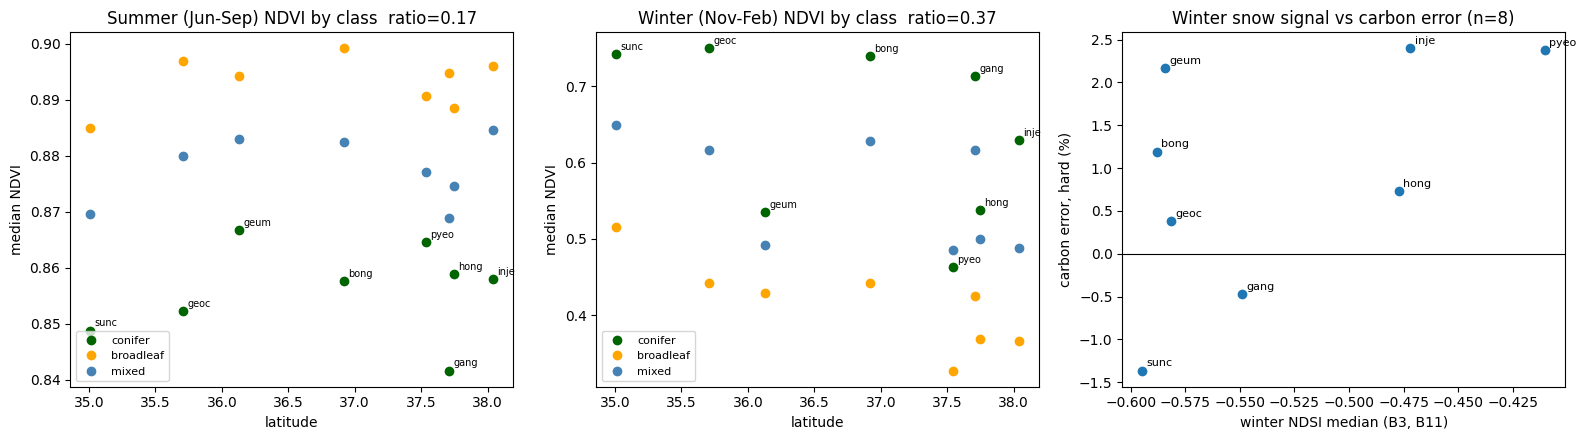

저장: diag_season_ratio.csv, diag_season_snow.csv, diag_season_medians.npz, diag_season.png
→ [5]·[6] 출력과 그림을 채팅에 붙여넣기


In [9]:
# [7] 그림·저장 (영문 표기)
lat = np.array([LAT[r] for r in TRAIN_REGIONS])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
cols = {0: 'darkgreen', 1: 'orange', 2: 'steelblue'}; names = {0: 'conifer', 1: 'broadleaf', 2: 'mixed'}
for k, s in enumerate(['여름', '겨울']):
    for c in range(3):
        ax[k].plot(lat, MED['NDVI'][s][:, c], 'o', c=cols[c], label=names[c])
    for j, r in enumerate(TRAIN_REGIONS):
        ax[k].annotate(r[:4], (lat[j], MED['NDVI'][s][j, 0]), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax[k].set_xlabel('latitude'); ax[k].set_ylabel('median NDVI')
    ax[k].set_title(f'{"Summer (Jun-Sep)" if s == "여름" else "Winter (Nov-Feb)"} NDVI by class  '
                    f'ratio={RES.loc["NDVI", s + " 비율"]:.2f}')
    ax[k].legend(fontsize=8)
SNr = pd.DataFrame(SNOW).set_index('지역')
ax[2].axhline(0, c='k', lw=.8)
ax[2].scatter(SNr['겨울NDSI_중앙값'], SNr['탄소오차'])
for r in TRAIN_REGIONS:
    ax[2].annotate(r[:4], (SNr.loc[r, '겨울NDSI_중앙값'], SNr.loc[r, '탄소오차']), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[2].set_xlabel('winter NDSI median (B3, B11)'); ax[2].set_ylabel('carbon error, hard (%)')
ax[2].set_title('Winter snow signal vs carbon error (n=8)')
plt.tight_layout(); plt.savefig(f'{OUT}/diag_season.png', dpi=150); plt.show()

RES.to_csv(f'{OUT}/diag_season_ratio.csv')
pd.DataFrame(SNOW).to_csv(f'{OUT}/diag_season_snow.csv', index=False)
np.savez(f'{OUT}/diag_season_medians.npz', **{f'{f}_{"s" if s == "여름" else "w"}': MED[f][s] for f in FEATS for s in ('여름', '겨울')},
         regions=np.array(TRAIN_REGIONS))
print('저장: diag_season_ratio.csv, diag_season_snow.csv, diag_season_medians.npz, diag_season.png')
print('→ [5]·[6] 출력과 그림을 채팅에 붙여넣기')
